In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display all columns when viewing the dataset
pd.set_option("display.max_columns", None)

# Set the visualization style
sns.set_style("whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load the raw dataset
df = pd.read_csv("../data/raw_data.csv")

# Display the first five rows
df.head()

,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,08-04-2024,True
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,23-07-2023,True
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,05-10-2022,False
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,07-05-2022,NaN
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,02-10-2022,False


In [3]:
print("Dataset Overview")
print("-" * 40)

print("Number of rows and columns:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

Dataset Overview
----------------------------------------
Number of rows and columns: (12575, 11)

Column Names:
['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit', 'Quantity', 'Total Spent', 'Payment Method', 'Location', 'Transaction Date', 'Discount Applied']

Data Types:
Transaction ID          str
Customer ID             str
Category                str
Item                    str
Price Per Unit      float64
Quantity            float64
Total Spent         float64
Payment Method          str
Location                str
Transaction Date        str
Discount Applied     object
dtype: object

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 12575 entries, 0 to 12574
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction ID    12575 non-null  str    
 1   Customer ID       12575 non-null  str    
 2   Category          12575 non-null  str    
 3   Item              11362

In [4]:
# Check missing values in each column
print("Missing Values:")
print(df.isnull().sum())

# Count duplicate rows
print("\nNumber of Duplicate Rows:")
print(df.duplicated().sum())

Missing Values:
Transaction ID         0
Customer ID            0
Category               0
Item                1213
Price Per Unit       609
Quantity             604
Total Spent          604
Payment Method         0
Location               0
Transaction Date       0
Discount Applied    4199
dtype: int64

Number of Duplicate Rows:
0


In [5]:
# Calculate missing values
missing_analysis = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df)) * 100
})

# Display columns with missing values
missing_analysis = missing_analysis[
    missing_analysis["Missing Values"] > 0
].sort_values(
    by="Missing Percentage",
    ascending=False
)

print("Missing Value Analysis")
display(missing_analysis.round(2))

Missing Value Analysis


,Missing Values,Missing Percentage
Discount Applied,4199,33.39
Item,1213,9.65
Price Per Unit,609,4.84
Quantity,604,4.80
Total Spent,604,4.80


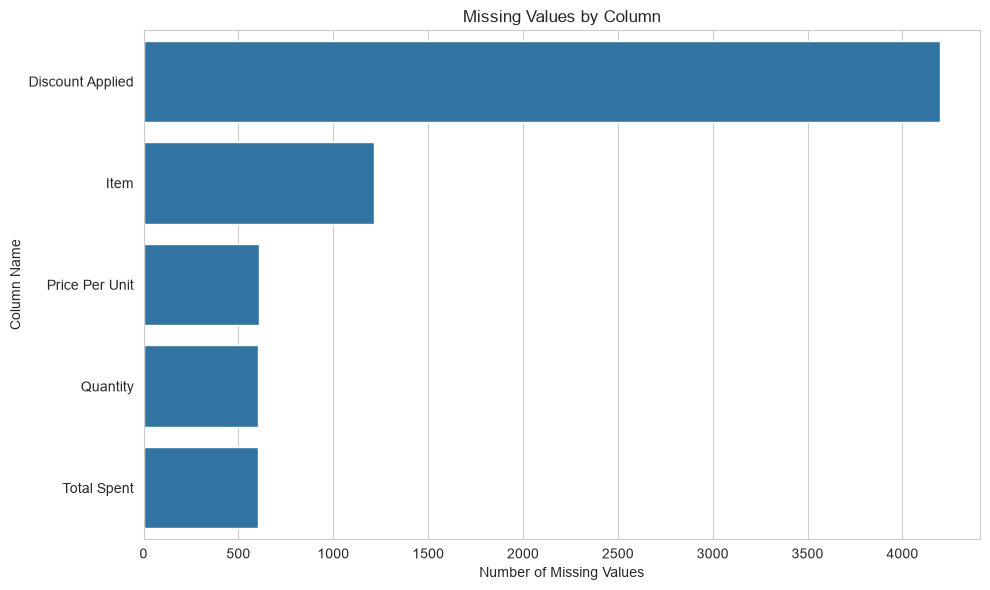

In [6]:
# Visualize missing values
missing_counts = df.isnull().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values(
    ascending=False
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=missing_counts.values,
    y=missing_counts.index
)

plt.title("Missing Values by Column")
plt.xlabel("Number of Missing Values")
plt.ylabel("Column Name")
plt.tight_layout()

# Save the visualization in the images folder
plt.savefig("../images/missing_values_before_cleaning.png", dpi=300)

plt.show()
plt.close()

In [7]:
# Inspect rows where Item is missing
print("Rows with missing Item:")
display(df[df["Item"].isnull()].head(10))

# Check whether Category is missing in these rows
print("\nMissing Category among rows with missing Item:")
print(df.loc[df["Item"].isnull(), "Category"].isnull().sum())

# Check missing values in the numerical columns
print("\nMissing numerical values:")
print(df[["Price Per Unit", "Quantity", "Total Spent"]].isnull().sum())

Rows with missing Item:


,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
5,TXN_7482416,CUST_09,Patisserie,NaN,NaN,10.0,200.0,Credit Card,Online,30-11-2023,NaN
7,TXN_1372952,CUST_21,Furniture,NaN,33.5,NaN,NaN,Digital Wallet,In-store,02-04-2024,True
11,TXN_5422631,CUST_09,Milk Products,NaN,NaN,8.0,52.0,Digital Wallet,In-store,12-01-2025,True
15,TXN_1809665,CUST_14,Beverages,NaN,24.5,NaN,NaN,Credit Card,In-store,11-05-2022,NaN
17,TXN_9634894,CUST_15,Milk Products,NaN,NaN,10.0,275.0,Digital Wallet,Online,17-04-2022,NaN
19,TXN_4206593,CUST_01,Furniture,NaN,35.0,NaN,NaN,Digital Wallet,Online,13-01-2025,False
21,TXN_8685338,CUST_15,Milk Products,NaN,NaN,3.0,105.0,Credit Card,In-store,29-10-2023,NaN
25,TXN_3481599,CUST_05,Furniture,NaN,39.5,NaN,NaN,Cash,Online,08-09-2022,False
32,TXN_1543244,CUST_20,Food,NaN,NaN,8.0,196.0,Credit Card,Online,25-10-2024,True
34,TXN_1621497,CUST_06,Patisserie,NaN,23.0,NaN,NaN,Cash,In-store,18-02-2023,NaN



Missing Category among rows with missing Item:
0

Missing numerical values:
Price Per Unit    609
Quantity          604
Total Spent       604
dtype: int64


In [8]:
# Examine the values in Discount Applied
print("Values in Discount Applied:")
print(df["Discount Applied"].value_counts(dropna=False))

# Display some rows where Discount Applied is missing
print("\nSample rows with missing Discount Applied:")
display(df[df["Discount Applied"].isnull()].head(10))

Values in Discount Applied:
Discount Applied
True     4219
NaN      4199
False    4157
Name: count, dtype: int64

Sample rows with missing Discount Applied:


,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,07-05-2022,NaN
5,TXN_7482416,CUST_09,Patisserie,NaN,NaN,10.0,200.0,Credit Card,Online,30-11-2023,NaN
14,TXN_2490363,CUST_09,Milk Products,Item_16_MILK,27.5,2.0,55.0,Digital Wallet,Online,22-05-2022,NaN
15,TXN_1809665,CUST_14,Beverages,NaN,24.5,NaN,NaN,Credit Card,In-store,11-05-2022,NaN
17,TXN_9634894,CUST_15,Milk Products,NaN,NaN,10.0,275.0,Digital Wallet,Online,17-04-2022,NaN
20,TXN_9939063,CUST_14,Beverages,Item_7_BEV,14.0,9.0,126.0,Digital Wallet,In-store,14-01-2024,NaN
21,TXN_8685338,CUST_15,Milk Products,NaN,NaN,3.0,105.0,Credit Card,In-store,29-10-2023,NaN
22,TXN_6547964,CUST_10,Electric household essentials,Item_4_EHE,9.5,7.0,66.5,Cash,In-store,15-08-2022,NaN
33,TXN_1494700,CUST_12,Electric household essentials,Item_21_EHE,35.0,9.0,315.0,Credit Card,In-store,07-03-2024,NaN
34,TXN_1621497,CUST_06,Patisserie,NaN,23.0,NaN,NaN,Cash,In-store,18-02-2023,NaN


In [9]:
# Inspect rows with missing values in the numerical columns
numeric_columns = ["Price Per Unit", "Quantity", "Total Spent"]

display(
    df[df[numeric_columns].isnull().any(axis=1)][
        ["Price Per Unit", "Quantity", "Total Spent"]
    ].head(15)
)

,Price Per Unit,Quantity,Total Spent
5,NaN,10.0,200.0
7,33.5,NaN,NaN
11,NaN,8.0,52.0
15,24.5,NaN,NaN
17,NaN,10.0,275.0
19,35.0,NaN,NaN
21,NaN,3.0,105.0
25,39.5,NaN,NaN
32,NaN,8.0,196.0
34,23.0,NaN,NaN


In [10]:
# Check whether Total Spent matches Price Per Unit * Quantity

complete_rows = df.dropna(
    subset=["Price Per Unit", "Quantity", "Total Spent"]
).copy()

complete_rows["Calculated Total"] = (
    complete_rows["Price Per Unit"] * complete_rows["Quantity"]
)

complete_rows["Difference"] = (
    complete_rows["Total Spent"] - complete_rows["Calculated Total"]
).round(2)

print("Rows with all three numerical values:", len(complete_rows))

print(
    "Rows where Total Spent differs from Price Per Unit * Quantity:",
    (complete_rows["Difference"].abs() > 0.01).sum()
)

display(
    complete_rows.loc[
        complete_rows["Difference"].abs() > 0.01,
        ["Price Per Unit", "Quantity", "Total Spent",
         "Calculated Total", "Difference"]
    ].head(10)
)

Rows with all three numerical values: 11362
Rows where Total Spent differs from Price Per Unit * Quantity: 0


,Price Per Unit,Quantity,Total Spent,Calculated Total,Difference


In [11]:
print("Transaction Date data type:")
print(df["Transaction Date"].dtype)

print("\nSample transaction dates:")
print(df["Transaction Date"].head(10).to_list())

Transaction Date data type:
str

Sample transaction dates:
['08-04-2024', '23-07-2023', '05-10-2022', '07-05-2022', '02-10-2022', '30-11-2023', '10-06-2023', '02-04-2024', '26-04-2023', '14-03-2024']


In [12]:
# Create a working copy of the original dataset
df_clean = df.copy()

print("Working copy created successfully!")
print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)

Working copy created successfully!
Original dataset shape: (12575, 11)
Working dataset shape: (12575, 11)


In [13]:
# Standardize column names
df_clean.columns = (
    df_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print("Updated column names:")
print(df_clean.columns.tolist())

Updated column names:
['transaction_id', 'customer_id', 'category', 'item', 'price_per_unit', 'quantity', 'total_spent', 'payment_method', 'location', 'transaction_date', 'discount_applied']


In [14]:
# Convert transaction_date into datetime format
df_clean["transaction_date"] = pd.to_datetime(
    df_clean["transaction_date"],
    format="%d-%m-%Y",
    errors="coerce"
)

print("Updated transaction date type:")
print(df_clean["transaction_date"].dtype)

print("\nSample converted dates:")
display(df_clean[["transaction_date"]].head(10))

Updated transaction date type:
datetime64[us]

Sample converted dates:


,transaction_date
0,2024-04-08
1,2023-07-23
2,2022-10-05
3,2022-05-07
4,2022-10-02
5,2023-11-30
6,2023-06-10
7,2024-04-02
8,2023-04-26
9,2024-03-14


In [15]:
# Count dates that are missing after conversion
print(
    "Missing transaction dates after conversion:",
    df_clean["transaction_date"].isna().sum()
)

Missing transaction dates after conversion: 0


In [16]:
# Count missing totals before cleaning
print(
    "Missing Total Spent before cleaning:",
    df_clean["total_spent"].isna().sum()
)

# Calculate missing totals when price and quantity are available
mask_total = (
    df_clean["total_spent"].isna()
    & df_clean["price_per_unit"].notna()
    & df_clean["quantity"].notna()
)

df_clean.loc[mask_total, "total_spent"] = (
    df_clean.loc[mask_total, "price_per_unit"]
    * df_clean.loc[mask_total, "quantity"]
)

print(
    "Missing Total Spent after calculation:",
    df_clean["total_spent"].isna().sum()
)

print("Totals recovered:", mask_total.sum())

Missing Total Spent before cleaning: 604
Missing Total Spent after calculation: 604
Totals recovered: 0


In [17]:
# Fill missing item descriptions with an explicit label
df_clean["item"] = df_clean["item"].fillna("Unknown")

print(
    "Missing Item values after cleaning:",
    df_clean["item"].isna().sum()
)

print("\nNumber of Unknown items:")
print((df_clean["item"] == "Unknown").sum())

Missing Item values after cleaning: 0

Number of Unknown items:
1213


In [18]:
# Examine missing discount values by category
print("Missing discounts by category:")
display(
    df_clean.loc[
        df_clean["discount_applied"].isna(),
        "category"
    ].value_counts()
)

# Examine missing discounts by payment method
print("\nMissing discounts by payment method:")
display(
    df_clean.loc[
        df_clean["discount_applied"].isna(),
        "payment_method"
    ].value_counts()
)

# Examine missing discounts by location
print("\nMissing discounts by location:")
display(
    df_clean.loc[
        df_clean["discount_applied"].isna(),
        "location"
    ].value_counts()
)

Missing discounts by category:


category
Furniture                             570
Beverages                             551
Electric household essentials         541
Food                                  533
Patisserie                            521
Butchers                              511
Milk Products                         495
Computers and electric accessories    477
Name: count, dtype: int64


Missing discounts by payment method:


payment_method
Cash              1473
Credit Card       1365
Digital Wallet    1361
Name: count, dtype: int64


Missing discounts by location:


location
Online      2103
In-store    2096
Name: count, dtype: int64

In [19]:
# Check missing numerical values
numeric_columns = [
    "price_per_unit",
    "quantity",
    "total_spent"
]

print("Missing values before numerical cleaning:")
display(df_clean[numeric_columns].isna().sum())

# Check how many rows have all three numerical values missing
print(
    "\nRows where all three numerical values are missing:",
    df_clean[numeric_columns].isna().all(axis=1).sum()
)

# Check rows where at least one numerical value is missing
print(
    "Rows with at least one missing numerical value:",
    df_clean[numeric_columns].isna().any(axis=1).sum()
)

Missing values before numerical cleaning:


price_per_unit    609
quantity          604
total_spent       604
dtype: int64


Rows where all three numerical values are missing: 0
Rows with at least one missing numerical value: 1213


In [20]:
# Check for duplicate rows
duplicate_count = df_clean.duplicated().sum()

print("Total duplicate rows:", duplicate_count)

# Display duplicate rows for inspection
duplicates = df_clean[df_clean.duplicated(keep=False)]

print("\nSample duplicate rows:")
display(duplicates.head(10))

Total duplicate rows: 0

Sample duplicate rows:


,transaction_id,customer_id,category,item,price_per_unit,quantity,total_spent,payment_method,location,transaction_date,discount_applied


In [21]:
# Analyze missing numerical values
numeric_columns = [
    "price_per_unit",
    "quantity",
    "total_spent"
]

missing_summary = pd.DataFrame({
    "Missing Values": df_clean[numeric_columns].isnull().sum(),
    "Missing Percentage": (
        df_clean[numeric_columns].isnull().sum()
        / len(df_clean)
    ) * 100
})

display(missing_summary.round(2))

,Missing Values,Missing Percentage
price_per_unit,609,4.84
quantity,604,4.80
total_spent,604,4.80


In [22]:
# Identify rows with missing totals
missing_total_rows = df_clean["total_spent"].isna()

# Count rows where price and quantity are both available
recoverable_totals = (
    missing_total_rows
    & df_clean["price_per_unit"].notna()
    & df_clean["quantity"].notna()
)

print(
    "Missing totals before recovery:",
    missing_total_rows.sum()
)

print(
    "Totals that can be recovered:",
    recoverable_totals.sum()
)

# Recover totals only when both inputs are available
df_clean.loc[recoverable_totals, "total_spent"] = (
    df_clean.loc[recoverable_totals, "price_per_unit"]
    * df_clean.loc[recoverable_totals, "quantity"]
)

print(
    "Missing totals after recovery:",
    df_clean["total_spent"].isna().sum()
)

Missing totals before recovery: 604
Totals that can be recovered: 0
Missing totals after recovery: 604


In [23]:
# Examine the discount column
print("Discount column data type:")
print(df_clean["discount_applied"].dtype)

print("\nExisting discount values:")
print(df_clean["discount_applied"].value_counts(dropna=False))

print("\nMissing discount values by category:")
display(
    df_clean.groupby("category")["discount_applied"]
    .apply(lambda x: x.isna().sum())
    .sort_values(ascending=False)
)

print("\nMissing discount values by location:")
display(
    df_clean.groupby("location")["discount_applied"]
    .apply(lambda x: x.isna().sum())
    .sort_values(ascending=False)
)

Discount column data type:
object

Existing discount values:
discount_applied
True     4219
NaN      4199
False    4157
Name: count, dtype: int64

Missing discount values by category:


category
Furniture                             570
Beverages                             551
Electric household essentials         541
Food                                  533
Patisserie                            521
Butchers                              511
Milk Products                         495
Computers and electric accessories    477
Name: discount_applied, dtype: int64


Missing discount values by location:


location
Online      2103
In-store    2096
Name: discount_applied, dtype: int64

In [24]:
# Inspect the original discount values
print("Unique discount values:")

print(
    df_clean["discount_applied"]
    .dropna()
    .unique()
)

print("\nData types of discount values:")

print(
    df_clean["discount_applied"]
    .dropna()
    .map(type)
    .value_counts()
)

Unique discount values:
[True False]

Data types of discount values:
discount_applied
<class 'bool'>    8376
Name: count, dtype: int64


In [25]:
# Check missing discount values
missing_discount = df_clean["discount_applied"].isna().sum()

# Calculate missing percentage
missing_percentage = (
    missing_discount / len(df_clean)
) * 100

print("Missing discount values:", missing_discount)
print(f"Missing percentage: {missing_percentage:.2f}%")

# Preserve missing values for now
print(
    "Missing values preserved:",
    df_clean["discount_applied"].isna().sum()
)

Missing discount values: 4199
Missing percentage: 33.39%
Missing values preserved: 4199


In [26]:
# Define numerical columns
numeric_columns = [
    "price_per_unit",
    "quantity",
    "total_spent"
]

# Check their data types
print("Data types before cleaning:")
print(df_clean[numeric_columns].dtypes)

# Check missing values
print("\nMissing values before cleaning:")
print(df_clean[numeric_columns].isnull().sum())

# Display sample rows with missing numerical values
print("\nSample rows with missing numerical values:")

display(
    df_clean.loc[
        df_clean[numeric_columns].isnull().any(axis=1),
        numeric_columns
    ].head(10)
)

Data types before cleaning:
price_per_unit    float64
quantity          float64
total_spent       float64
dtype: object

Missing values before cleaning:
price_per_unit    609
quantity          604
total_spent       604
dtype: int64

Sample rows with missing numerical values:


,price_per_unit,quantity,total_spent
5,NaN,10.0,200.0
7,33.5,NaN,NaN
11,NaN,8.0,52.0
15,24.5,NaN,NaN
17,NaN,10.0,275.0
19,35.0,NaN,NaN
21,NaN,3.0,105.0
25,39.5,NaN,NaN
32,NaN,8.0,196.0
34,23.0,NaN,NaN


In [27]:
# Identify missing values in the numerical columns
missing_price = df_clean["price_per_unit"].isna()
missing_quantity = df_clean["quantity"].isna()
missing_total = df_clean["total_spent"].isna()

# Count values that may be recoverable
recoverable_price = (
    missing_price
    & df_clean["quantity"].notna()
    & df_clean["total_spent"].notna()
    & (df_clean["quantity"] != 0)
)

recoverable_total = (
    missing_total
    & df_clean["price_per_unit"].notna()
    & df_clean["quantity"].notna()
)

recoverable_quantity = (
    missing_quantity
    & df_clean["price_per_unit"].notna()
    & df_clean["total_spent"].notna()
    & (df_clean["price_per_unit"] != 0)
)

print("Missing prices that may be recovered:", recoverable_price.sum())
print("Missing quantities that may be recovered:", recoverable_quantity.sum())
print("Missing totals that may be recovered:", recoverable_total.sum())

Missing prices that may be recovered: 609
Missing quantities that may be recovered: 0
Missing totals that may be recovered: 0


In [28]:
# Select rows where all three numerical values are available
complete_rows = df_clean.dropna(
    subset=["price_per_unit", "quantity", "total_spent"]
).copy()

# Calculate total using price per unit and quantity
complete_rows["calculated_total"] = (
    complete_rows["price_per_unit"] * complete_rows["quantity"]
)

# Calculate the difference
complete_rows["difference"] = (
    complete_rows["total_spent"] - complete_rows["calculated_total"]
).abs()

# Check how many rows match within a small tolerance
matching_rows = (
    complete_rows["difference"] <= 0.01
).sum()

print("Rows checked:", len(complete_rows))
print("Rows matching the calculation:", matching_rows)

print(
    "Percentage matching:",
    round(matching_rows / len(complete_rows) * 100, 2),
    "%"
)

Rows checked: 11362
Rows matching the calculation: 11362
Percentage matching: 100.0 %


In [29]:
# Step 1: Recover missing prices
recoverable_price = (
    df_clean["price_per_unit"].isna()
    & df_clean["quantity"].notna()
    & df_clean["total_spent"].notna()
    & (df_clean["quantity"] != 0)
)

df_clean.loc[recoverable_price, "price_per_unit"] = (
    df_clean.loc[recoverable_price, "total_spent"]
    / df_clean.loc[recoverable_price, "quantity"]
)

print("Prices recovered:", recoverable_price.sum())


# Step 2: Recover missing total_spent values
recoverable_total = (
    df_clean["total_spent"].isna()
    & df_clean["price_per_unit"].notna()
    & df_clean["quantity"].notna()
)

df_clean.loc[recoverable_total, "total_spent"] = (
    df_clean.loc[recoverable_total, "price_per_unit"]
    * df_clean.loc[recoverable_total, "quantity"]
)

print("Total spent values recovered:", recoverable_total.sum())


# Step 3: Check remaining missing values
print("\nRemaining missing numerical values:")
print(
    df_clean[
        ["price_per_unit", "quantity", "total_spent"]
    ].isna().sum()
)

Prices recovered: 609
Total spent values recovered: 0

Remaining missing numerical values:
price_per_unit      0
quantity          604
total_spent       604
dtype: int64


In [30]:
# Check whether quantity and total_spent are missing in the same rows

missing_quantity = df_clean["quantity"].isna()
missing_total = df_clean["total_spent"].isna()

print("Rows with missing quantity:", missing_quantity.sum())
print("Rows with missing total_spent:", missing_total.sum())

print(
    "Rows where both are missing:",
    (missing_quantity & missing_total).sum()
)

print(
    "Quantity missing but total_spent available:",
    (missing_quantity & df_clean["total_spent"].notna()).sum()
)

print(
    "Total_spent missing but quantity available:",
    (missing_total & df_clean["quantity"].notna()).sum()
)

Rows with missing quantity: 604
Rows with missing total_spent: 604
Rows where both are missing: 604
Quantity missing but total_spent available: 0
Total_spent missing but quantity available: 0


In [31]:
# Inspect rows where quantity and total_spent are both missing

missing_rows = df_clean[
    df_clean["quantity"].isna()
    & df_clean["total_spent"].isna()
]

print("Number of affected rows:", len(missing_rows))

display(missing_rows.head(10))

Number of affected rows: 604


,transaction_id,customer_id,category,item,price_per_unit,quantity,total_spent,payment_method,location,transaction_date,discount_applied
7,TXN_1372952,CUST_21,Furniture,Unknown,33.5,NaN,NaN,Digital Wallet,In-store,2024-04-02,True
15,TXN_1809665,CUST_14,Beverages,Unknown,24.5,NaN,NaN,Credit Card,In-store,2022-05-11,NaN
19,TXN_4206593,CUST_01,Furniture,Unknown,35.0,NaN,NaN,Digital Wallet,Online,2025-01-13,False
25,TXN_3481599,CUST_05,Furniture,Unknown,39.5,NaN,NaN,Cash,Online,2022-09-08,False
34,TXN_1621497,CUST_06,Patisserie,Unknown,23.0,NaN,NaN,Cash,In-store,2023-02-18,NaN
83,TXN_4532214,CUST_25,Patisserie,Unknown,15.5,NaN,NaN,Credit Card,In-store,2024-03-25,False
112,TXN_5419965,CUST_23,Computers and electric accessories,Unknown,20.0,NaN,NaN,Digital Wallet,Online,2024-01-16,False
114,TXN_8210621,CUST_03,Beverages,Unknown,39.5,NaN,NaN,Digital Wallet,Online,2024-01-03,False
118,TXN_8586300,CUST_11,Computers and electric accessories,Unknown,27.5,NaN,NaN,Credit Card,Online,2022-02-08,False
138,TXN_1154680,CUST_25,Furniture,Unknown,35.0,NaN,NaN,Credit Card,Online,2022-12-18,False


In [32]:
# Create a complete missing-value summary

missing_summary = pd.DataFrame({
    "Missing Values": df_clean.isna().sum(),
    "Missing Percentage": (
        df_clean.isna().sum() / len(df_clean) * 100
    ).round(2)
})

# Show columns with missing values
missing_summary = missing_summary[
    missing_summary["Missing Values"] > 0
].sort_values(
    by="Missing Values",
    ascending=False
)

display(missing_summary)

,Missing Values,Missing Percentage
discount_applied,4199,33.39
quantity,604,4.80
total_spent,604,4.80


In [33]:
# Investigate missing discount values

missing_discount = df_clean["discount_applied"].isna()

print("Total missing discount values:", missing_discount.sum())

print("\nMissing discounts by category:")
display(
    df_clean.loc[missing_discount, "category"]
    .value_counts(dropna=False)
)

print("\nMissing discounts by location:")
display(
    df_clean.loc[missing_discount, "location"]
    .value_counts(dropna=False)
)

print("\nSample rows with missing discounts:")
display(
    df_clean.loc[
        missing_discount,
        [
            "transaction_id",
            "category",
            "item",
            "price_per_unit",
            "quantity",
            "total_spent",
            "location",
            "discount_applied"
        ]
    ].head(10)
)

Total missing discount values: 4199

Missing discounts by category:


category
Furniture                             570
Beverages                             551
Electric household essentials         541
Food                                  533
Patisserie                            521
Butchers                              511
Milk Products                         495
Computers and electric accessories    477
Name: count, dtype: int64


Missing discounts by location:


location
Online      2103
In-store    2096
Name: count, dtype: int64


Sample rows with missing discounts:


,transaction_id,category,item,price_per_unit,quantity,total_spent,location,discount_applied
3,TXN_9458126,Beverages,Item_16_BEV,27.5,9.0,247.5,Online,NaN
5,TXN_7482416,Patisserie,Unknown,20.0,10.0,200.0,Online,NaN
14,TXN_2490363,Milk Products,Item_16_MILK,27.5,2.0,55.0,Online,NaN
15,TXN_1809665,Beverages,Unknown,24.5,NaN,NaN,In-store,NaN
17,TXN_9634894,Milk Products,Unknown,27.5,10.0,275.0,Online,NaN
20,TXN_9939063,Beverages,Item_7_BEV,14.0,9.0,126.0,In-store,NaN
21,TXN_8685338,Milk Products,Unknown,35.0,3.0,105.0,In-store,NaN
22,TXN_6547964,Electric household essentials,Item_4_EHE,9.5,7.0,66.5,In-store,NaN
33,TXN_1494700,Electric household essentials,Item_21_EHE,35.0,9.0,315.0,In-store,NaN
34,TXN_1621497,Patisserie,Unknown,23.0,NaN,NaN,In-store,NaN


In [34]:
# Standardize the discount_applied column

df_clean["discount_applied"] = (
    df_clean["discount_applied"]
    .map({
        True: True,
        False: False
    })
    .astype("boolean")
)

# Check the results

print("Discount column data type:")
print(df_clean["discount_applied"].dtype)

print("\nDiscount values after standardization:")
print(df_clean["discount_applied"].value_counts(dropna=False))

print("\nMissing discount values:")
print(df_clean["discount_applied"].isna().sum())

Discount column data type:
boolean

Discount values after standardization:
discount_applied
True     4219
<NA>     4199
False    4157
Name: count, dtype: Int64

Missing discount values:
4199


In [35]:
# Check missing and unknown item values

print("Missing item values:")
print(df_clean["item"].isna().sum())

print("\nNumber of Unknown item values:")
print(
    df_clean["item"]
    .astype("string")
    .str.strip()
    .str.lower()
    .eq("unknown")
    .sum()
)

print("\nMost frequent item values:")
print(df_clean["item"].value_counts(dropna=False).head(15))

Missing item values:
0

Number of Unknown item values:
1213

Most frequent item values:
item
Unknown         1213
Item_2_BEV       126
Item_25_FUR      113
Item_11_FUR      110
Item_16_MILK     109
Item_1_MILK      109
Item_20_BUT      107
Item_5_FUR       107
Item_14_FOOD     106
Item_11_MILK     106
Item_19_CEA      106
Item_19_MILK     105
Item_24_FUR      105
Item_8_EHE       105
Item_13_FOOD     101
Name: count, dtype: int64


In [36]:
# Identify text columns
text_columns = df_clean.select_dtypes(
    include=["object", "string"]
).columns

print("Text columns:")
print(text_columns.tolist())

# Remove unnecessary spaces from text values
for column in text_columns:
    df_clean[column] = df_clean[column].apply(
        lambda value: value.strip()
        if isinstance(value, str)
        else value
    )

print("\nText standardization completed!")

# Display sample cleaned values
display(df_clean[text_columns].head(10))

Text columns:
['transaction_id', 'customer_id', 'category', 'item', 'payment_method', 'location']

Text standardization completed!


,transaction_id,customer_id,category,item,payment_method,location
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,Digital Wallet,Online
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,Digital Wallet,Online
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,Credit Card,Online
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,Credit Card,Online
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,Digital Wallet,Online
5,TXN_7482416,CUST_09,Patisserie,Unknown,Credit Card,Online
6,TXN_3652209,CUST_07,Food,Item_1_FOOD,Credit Card,In-store
7,TXN_1372952,CUST_21,Furniture,Unknown,Digital Wallet,In-store
8,TXN_9728486,CUST_23,Furniture,Item_16_FUR,Credit Card,In-store
9,TXN_2722661,CUST_25,Butchers,Item_22_BUT,Cash,Online


In [37]:
# Check the final status of the discount_applied column

print("Discount values after standardization:")
print(df_clean["discount_applied"].value_counts(dropna=False))

print("\nMissing discount values:")
print(df_clean["discount_applied"].isna().sum())

print("\nDiscount column data type:")
print(df_clean["discount_applied"].dtype)

Discount values after standardization:
discount_applied
True     4219
<NA>     4199
False    4157
Name: count, dtype: Int64

Missing discount values:
4199

Discount column data type:
boolean


In [38]:
# Check missing numerical values after recovery

numerical_columns = [
    "price_per_unit",
    "quantity",
    "total_spent"
]

print("Missing values after recovery:")
print(df_clean[numerical_columns].isna().sum())

print("\nMissing percentage after recovery:")
print(
    (df_clean[numerical_columns].isna().sum() / len(df_clean) * 100)
    .round(2)
)

# Display rows with missing quantity or total_spent
remaining_missing = df_clean[
    df_clean[["quantity", "total_spent"]].isna().any(axis=1)
]

print("\nRows with missing quantity or total_spent:")
print(len(remaining_missing))

display(remaining_missing.head(10))

Missing values after recovery:
price_per_unit      0
quantity          604
total_spent       604
dtype: int64

Missing percentage after recovery:
price_per_unit    0.0
quantity          4.8
total_spent       4.8
dtype: float64

Rows with missing quantity or total_spent:
604


,transaction_id,customer_id,category,item,price_per_unit,quantity,total_spent,payment_method,location,transaction_date,discount_applied
7,TXN_1372952,CUST_21,Furniture,Unknown,33.5,NaN,NaN,Digital Wallet,In-store,2024-04-02,True
15,TXN_1809665,CUST_14,Beverages,Unknown,24.5,NaN,NaN,Credit Card,In-store,2022-05-11,<NA>
19,TXN_4206593,CUST_01,Furniture,Unknown,35.0,NaN,NaN,Digital Wallet,Online,2025-01-13,False
25,TXN_3481599,CUST_05,Furniture,Unknown,39.5,NaN,NaN,Cash,Online,2022-09-08,False
34,TXN_1621497,CUST_06,Patisserie,Unknown,23.0,NaN,NaN,Cash,In-store,2023-02-18,<NA>
83,TXN_4532214,CUST_25,Patisserie,Unknown,15.5,NaN,NaN,Credit Card,In-store,2024-03-25,False
112,TXN_5419965,CUST_23,Computers and electric accessories,Unknown,20.0,NaN,NaN,Digital Wallet,Online,2024-01-16,False
114,TXN_8210621,CUST_03,Beverages,Unknown,39.5,NaN,NaN,Digital Wallet,Online,2024-01-03,False
118,TXN_8586300,CUST_11,Computers and electric accessories,Unknown,27.5,NaN,NaN,Credit Card,Online,2022-02-08,False
138,TXN_1154680,CUST_25,Furniture,Unknown,35.0,NaN,NaN,Credit Card,Online,2022-12-18,False


In [39]:
# Check for duplicate rows

print("Total rows before duplicate removal:", len(df_clean))

# Count complete duplicate rows
duplicate_count = df_clean.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

# Display duplicate rows, if any
duplicates = df_clean[df_clean.duplicated(keep=False)]

print("\nSample duplicate rows:")
display(duplicates.head(10))

Total rows before duplicate removal: 12575
Number of duplicate rows: 0

Sample duplicate rows:


,transaction_id,customer_id,category,item,price_per_unit,quantity,total_spent,payment_method,location,transaction_date,discount_applied


In [40]:
# Check for duplicate transaction IDs

duplicate_transactions = df_clean[
    df_clean["transaction_id"].duplicated(keep=False)
]

print(
    "Number of rows with duplicate transaction IDs:",
    len(duplicate_transactions)
)

print(
    "Number of unique duplicated transaction IDs:",
    duplicate_transactions["transaction_id"].nunique()
)

display(duplicate_transactions.head(10))

Number of rows with duplicate transaction IDs: 0
Number of unique duplicated transaction IDs: 0


,transaction_id,customer_id,category,item,price_per_unit,quantity,total_spent,payment_method,location,transaction_date,discount_applied


In [41]:
# Check for zero and negative numerical values

numerical_columns = [
    "price_per_unit",
    "quantity",
    "total_spent"
]

for column in numerical_columns:
    print(f"\n--- {column} ---")

    print("Zero values:", (df_clean[column] == 0).sum())

    print("Negative values:", (df_clean[column] < 0).sum())

    print("Minimum value:", df_clean[column].min())

    print("Maximum value:", df_clean[column].max())


--- price_per_unit ---
Zero values: 0
Negative values: 0
Minimum value: 5.0
Maximum value: 41.0

--- quantity ---
Zero values: 0
Negative values: 0
Minimum value: 1.0
Maximum value: 10.0

--- total_spent ---
Zero values: 0
Negative values: 0
Minimum value: 5.0
Maximum value: 410.0


In [42]:
# Check whether total_spent matches price_per_unit * quantity

complete_rows = df_clean.dropna(
    subset=["price_per_unit", "quantity", "total_spent"]
).copy()

complete_rows["calculated_total"] = (
    complete_rows["price_per_unit"] * complete_rows["quantity"]
)

complete_rows["difference"] = (
    complete_rows["total_spent"] - complete_rows["calculated_total"]
).abs()

print("Rows checked:", len(complete_rows))

print(
    "Rows where total_spent matches the calculation:",
    (complete_rows["difference"] < 0.01).sum()
)

print(
    "Rows where total_spent does not match:",
    (complete_rows["difference"] >= 0.01).sum()
)

print("\nSample rows where values do not match:")

display(
    complete_rows.loc[
        complete_rows["difference"] >= 0.01,
        [
            "price_per_unit",
            "quantity",
            "total_spent",
            "calculated_total",
            "difference"
        ]
    ].head(10)
)

Rows checked: 11971
Rows where total_spent matches the calculation: 11971
Rows where total_spent does not match: 0

Sample rows where values do not match:


,price_per_unit,quantity,total_spent,calculated_total,difference


In [43]:
# Count rows where only one value is missing

quantity_missing = (
    df_clean["quantity"].isna()
    & df_clean["total_spent"].notna()
)

total_spent_missing = (
    df_clean["total_spent"].isna()
    & df_clean["quantity"].notna()
)

both_missing = (
    df_clean["quantity"].isna()
    & df_clean["total_spent"].isna()
)

print("Quantity missing, total_spent available:", quantity_missing.sum())
print("Total_spent missing, quantity available:", total_spent_missing.sum())
print("Both quantity and total_spent missing:", both_missing.sum())

Quantity missing, total_spent available: 0
Total_spent missing, quantity available: 0
Both quantity and total_spent missing: 604


In [44]:
# Investigate rows with missing quantity and total_spent

missing_rows = df_clean[
    df_clean["quantity"].isna()
    & df_clean["total_spent"].isna()
]

print("Total affected rows:", len(missing_rows))

print("\nItem values in affected rows:")
print(missing_rows["item"].value_counts(dropna=False))

print("\nCategory values in affected rows:")
print(missing_rows["category"].value_counts(dropna=False))

print("\nPrice per unit summary:")
print(missing_rows["price_per_unit"].describe())

print("\nSample affected rows:")
display(missing_rows.head(10))

Total affected rows: 604

Item values in affected rows:
item
Unknown    604
Name: count, dtype: int64

Category values in affected rows:
category
Patisserie                            87
Computers and electric accessories    81
Food                                  81
Electric household essentials         75
Butchers                              72
Beverages                             71
Milk Products                         71
Furniture                             66
Name: count, dtype: int64

Price per unit summary:
count    604.000000
mean      23.536424
std       10.891040
min        5.000000
25%       14.000000
50%       23.000000
75%       33.500000
max       41.000000
Name: price_per_unit, dtype: float64

Sample affected rows:


,transaction_id,customer_id,category,item,price_per_unit,quantity,total_spent,payment_method,location,transaction_date,discount_applied
7,TXN_1372952,CUST_21,Furniture,Unknown,33.5,NaN,NaN,Digital Wallet,In-store,2024-04-02,True
15,TXN_1809665,CUST_14,Beverages,Unknown,24.5,NaN,NaN,Credit Card,In-store,2022-05-11,<NA>
19,TXN_4206593,CUST_01,Furniture,Unknown,35.0,NaN,NaN,Digital Wallet,Online,2025-01-13,False
25,TXN_3481599,CUST_05,Furniture,Unknown,39.5,NaN,NaN,Cash,Online,2022-09-08,False
34,TXN_1621497,CUST_06,Patisserie,Unknown,23.0,NaN,NaN,Cash,In-store,2023-02-18,<NA>
83,TXN_4532214,CUST_25,Patisserie,Unknown,15.5,NaN,NaN,Credit Card,In-store,2024-03-25,False
112,TXN_5419965,CUST_23,Computers and electric accessories,Unknown,20.0,NaN,NaN,Digital Wallet,Online,2024-01-16,False
114,TXN_8210621,CUST_03,Beverages,Unknown,39.5,NaN,NaN,Digital Wallet,Online,2024-01-03,False
118,TXN_8586300,CUST_11,Computers and electric accessories,Unknown,27.5,NaN,NaN,Credit Card,Online,2022-02-08,False
138,TXN_1154680,CUST_25,Furniture,Unknown,35.0,NaN,NaN,Credit Card,Online,2022-12-18,False


In [45]:
# Create a copy of the cleaned dataset before handling missing values

df_before_missing_handling = df_clean.copy()

# Count missing values before handling them

print("Missing values before handling:")
print(
    df_clean[["quantity", "total_spent"]]
    .isna()
    .sum()
)

# Calculate the percentage of affected rows

affected_percentage = (
    df_clean["quantity"].isna().sum()
    / len(df_clean)
) * 100

print(
    f"\nPercentage of rows with missing quantity: "
    f"{affected_percentage:.2f}%"
)

Missing values before handling:
quantity       604
total_spent    604
dtype: int64

Percentage of rows with missing quantity: 4.80%


In [46]:
# Count rows before removing records with missing transaction values
rows_before = len(df_clean)

# Identify rows where both quantity and total_spent are missing
missing_transaction_values = (
    df_clean["quantity"].isna()
    & df_clean["total_spent"].isna()
)

# Count affected rows
rows_removed = missing_transaction_values.sum()

# Remove these rows
df_clean = df_clean.loc[~missing_transaction_values].copy()

# Report the results
print("Rows before handling missing values:", rows_before)
print("Rows removed:", rows_removed)
print("Rows remaining:", len(df_clean))

print("\nRemaining missing values:")
print(df_clean[["quantity", "total_spent"]].isna().sum())

Rows before handling missing values: 12575
Rows removed: 604
Rows remaining: 11971

Remaining missing values:
quantity       0
total_spent    0
dtype: int64


In [47]:
# Verify the dataset after missing-value handling

print("Dataset shape after cleaning:", df_clean.shape)

print("\nMissing values in each column:")
print(df_clean.isnull().sum())

print("\nTotal missing values:", df_clean.isnull().sum().sum())

print("\nFirst 5 rows of the cleaned dataset:")
display(df_clean.head())

print("\nDataset information:")
df_clean.info()

Dataset shape after cleaning: (11971, 11)

Missing values in each column:
transaction_id         0
customer_id            0
category               0
item                   0
price_per_unit         0
quantity               0
total_spent            0
payment_method         0
location               0
transaction_date       0
discount_applied    3988
dtype: int64

Total missing values: 3988

First 5 rows of the cleaned dataset:


,transaction_id,customer_id,category,item,price_per_unit,quantity,total_spent,payment_method,location,transaction_date,discount_applied
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,True
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,True
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,False
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,<NA>
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,False



Dataset information:
<class 'pandas.DataFrame'>
Index: 11971 entries, 0 to 12574
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   transaction_id    11971 non-null  str           
 1   customer_id       11971 non-null  str           
 2   category          11971 non-null  str           
 3   item              11971 non-null  str           
 4   price_per_unit    11971 non-null  float64       
 5   quantity          11971 non-null  float64       
 6   total_spent       11971 non-null  float64       
 7   payment_method    11971 non-null  str           
 8   location          11971 non-null  str           
 9   transaction_date  11971 non-null  datetime64[us]
 10  discount_applied  7983 non-null   boolean       
dtypes: boolean(1), datetime64[us](1), float64(3), str(6)
memory usage: 1.0 MB


In [48]:
# Investigate missing discount values

print("Discount values before handling:")
print(df_clean["discount_applied"].value_counts(dropna=False))

print("\nMissing discount values:")
print(df_clean["discount_applied"].isna().sum())

print("\nPercentage of missing discount values:")
missing_percentage = (
    df_clean["discount_applied"].isna().sum()
    / len(df_clean)
) * 100

print(f"{missing_percentage:.2f}%")

# Display sample rows with missing discounts
print("\nSample rows with missing discounts:")
display(
    df_clean[df_clean["discount_applied"].isna()].head(10)
)

Discount values before handling:
discount_applied
True     4019
<NA>     3988
False    3964
Name: count, dtype: Int64

Missing discount values:
3988

Percentage of missing discount values:
33.31%

Sample rows with missing discounts:


,transaction_id,customer_id,category,item,price_per_unit,quantity,total_spent,payment_method,location,transaction_date,discount_applied
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,<NA>
5,TXN_7482416,CUST_09,Patisserie,Unknown,20.0,10.0,200.0,Credit Card,Online,2023-11-30,<NA>
14,TXN_2490363,CUST_09,Milk Products,Item_16_MILK,27.5,2.0,55.0,Digital Wallet,Online,2022-05-22,<NA>
17,TXN_9634894,CUST_15,Milk Products,Unknown,27.5,10.0,275.0,Digital Wallet,Online,2022-04-17,<NA>
20,TXN_9939063,CUST_14,Beverages,Item_7_BEV,14.0,9.0,126.0,Digital Wallet,In-store,2024-01-14,<NA>
21,TXN_8685338,CUST_15,Milk Products,Unknown,35.0,3.0,105.0,Credit Card,In-store,2023-10-29,<NA>
22,TXN_6547964,CUST_10,Electric household essentials,Item_4_EHE,9.5,7.0,66.5,Cash,In-store,2022-08-15,<NA>
33,TXN_1494700,CUST_12,Electric household essentials,Item_21_EHE,35.0,9.0,315.0,Credit Card,In-store,2024-03-07,<NA>
38,TXN_8312797,CUST_14,Beverages,Item_11_BEV,20.0,5.0,100.0,Digital Wallet,Online,2022-06-03,<NA>
41,TXN_1019817,CUST_16,Electric household essentials,Item_10_EHE,18.5,5.0,92.5,Cash,Online,2022-08-01,<NA>


In [49]:
# Investigate missing discount values by category

missing_discount = df_clean["discount_applied"].isna()

print("Missing discounts by payment method:")
print(
    df_clean.loc[missing_discount, "payment_method"]
    .value_counts(dropna=False)
)

print("\nMissing discounts by location:")
print(
    df_clean.loc[missing_discount, "location"]
    .value_counts(dropna=False)
)

print("\nMissing discounts by category:")
print(
    df_clean.loc[missing_discount, "category"]
    .value_counts(dropna=False)
)

print("\nDiscount status by location:")
display(
    pd.crosstab(
        df_clean["location"],
        df_clean["discount_applied"],
        dropna=False
    )
)

Missing discounts by payment method:
payment_method
Cash              1398
Credit Card       1296
Digital Wallet    1294
Name: count, dtype: int64

Missing discounts by location:
location
Online      2008
In-store    1980
Name: count, dtype: int64

Missing discounts by category:
category
Furniture                             542
Beverages                             528
Electric household essentials         516
Food                                  500
Butchers                              487
Patisserie                            486
Milk Products                         476
Computers and electric accessories    453
Name: count, dtype: int64

Discount status by location:


discount_applied,False,True,<NA>
location,,,
In-store,1961,1962,1980
Online,2003,2057,2008


In [50]:
# Investigate unknown item values

unknown_items = (
    df_clean["item"]
    .astype("string")
    .str.strip()
    .str.lower()
    .eq("unknown")
)

print("Total unknown item values:", unknown_items.sum())

print(
    "Percentage of unknown item values:",
    f"{unknown_items.mean() * 100:.2f}%"
)

print("\nUnknown items by category:")

print(
    df_clean.loc[unknown_items, "category"]
    .value_counts()
)

print("\nSample rows with unknown items:")

display(
    df_clean.loc[unknown_items].head(10)
)

Total unknown item values: 609
Percentage of unknown item values: 5.09%

Unknown items by category:
category
Milk Products                         88
Food                                  81
Computers and electric accessories    80
Electric household essentials         79
Butchers                              75
Patisserie                            72
Beverages                             69
Furniture                             65
Name: count, dtype: int64

Sample rows with unknown items:


,transaction_id,customer_id,category,item,price_per_unit,quantity,total_spent,payment_method,location,transaction_date,discount_applied
5,TXN_7482416,CUST_09,Patisserie,Unknown,20.0,10.0,200.0,Credit Card,Online,2023-11-30,<NA>
11,TXN_5422631,CUST_09,Milk Products,Unknown,6.5,8.0,52.0,Digital Wallet,In-store,2025-01-12,True
17,TXN_9634894,CUST_15,Milk Products,Unknown,27.5,10.0,275.0,Digital Wallet,Online,2022-04-17,<NA>
21,TXN_8685338,CUST_15,Milk Products,Unknown,35.0,3.0,105.0,Credit Card,In-store,2023-10-29,<NA>
32,TXN_1543244,CUST_20,Food,Unknown,24.5,8.0,196.0,Credit Card,Online,2024-10-25,True
127,TXN_4608122,CUST_21,Butchers,Unknown,27.5,10.0,275.0,Digital Wallet,Online,2022-10-01,False
159,TXN_3822751,CUST_21,Butchers,Unknown,14.0,9.0,126.0,Digital Wallet,In-store,2024-03-04,False
216,TXN_7804271,CUST_22,Patisserie,Unknown,5.0,8.0,40.0,Cash,Online,2023-02-10,<NA>
247,TXN_3433195,CUST_24,Electric household essentials,Unknown,21.5,7.0,150.5,Cash,Online,2023-03-30,<NA>
271,TXN_7571093,CUST_17,Milk Products,Unknown,11.0,9.0,99.0,Digital Wallet,In-store,2022-11-18,<NA>


In [51]:
# Handle unknown item values

unknown_before = (
    df_clean["item"]
    .astype("string")
    .str.strip()
    .str.lower()
    .eq("unknown")
    .sum()
)

print("Unknown item values retained:", unknown_before)

# Standardize item text
df_clean["item"] = (
    df_clean["item"]
    .astype("string")
    .str.strip()
)

print(
    "Unknown item values after standardization:",
    df_clean["item"].str.lower().eq("unknown").sum()
)

print("\nDataset shape:", df_clean.shape)

Unknown item values retained: 609
Unknown item values after standardization: 609

Dataset shape: (11971, 11)


In [52]:
# Final missing-value assessment

print("Missing values in each column:")
print(df_clean.isna().sum())

print("\nTotal missing values:")
print(df_clean.isna().sum().sum())

print("\nMissing discount percentage:")
print(
    f"{df_clean['discount_applied'].isna().mean() * 100:.2f}%"
)

Missing values in each column:
transaction_id         0
customer_id            0
category               0
item                   0
price_per_unit         0
quantity               0
total_spent            0
payment_method         0
location               0
transaction_date       0
discount_applied    3988
dtype: int64

Total missing values:
3988

Missing discount percentage:
33.31%


### Handling Missing Values in `discount_applied`

The `discount_applied` column contains 3,988 missing values,
representing approximately 33.31% of the dataset after cleaning.

These values were retained as missing because the available
data does not establish whether a discount was applied to
these transactions.

The missing values were not replaced with True or False,
and the corresponding transaction rows were not removed.
This approach preserves the original information and avoids
introducing unsupported assumptions.

In [53]:
# Final data validation

print("Dataset shape:", df_clean.shape)

print("\nDuplicate rows:", df_clean.duplicated().sum())

print(
    "Duplicate transaction IDs:",
    df_clean["transaction_id"].duplicated().sum()
)

print(
    "Missing transaction IDs:",
    df_clean["transaction_id"].isna().sum()
)

print(
    "Invalid transaction dates:",
    df_clean["transaction_date"].isna().sum()
)

print(
    "Non-positive prices:",
    (df_clean["price_per_unit"] <= 0).sum()
)

print(
    "Non-positive quantities:",
    (df_clean["quantity"] <= 0).sum()
)

print(
    "Rows where total_spent does not match price × quantity:",
    (
        (df_clean["total_spent"] -
         df_clean["price_per_unit"] * df_clean["quantity"]).abs()
        >= 0.01
    ).sum()
)

Dataset shape: (11971, 11)

Duplicate rows: 0
Duplicate transaction IDs: 0
Missing transaction IDs: 0
Invalid transaction dates: 0
Non-positive prices: 0
Non-positive quantities: 0
Rows where total_spent does not match price × quantity: 0


In [54]:
from pathlib import Path

# Create the processed folder in the project root
project_root = Path.cwd().parent
processed_folder = project_root / "processed"
processed_folder.mkdir(parents=True, exist_ok=True)

# Export the cleaned dataset
output_path = processed_folder / "cleaned_retail_data.csv"

df_clean.to_csv(output_path, index=False)

print("Cleaned dataset saved successfully!")
print("File location:", output_path.resolve())
print("Final rows:", len(df_clean))
print("Final columns:", len(df_clean.columns))

Cleaned dataset saved successfully!
File location: C:\Users\RAM CHOUDHARY\Desktop\Oasis_Data_Cleaning\processed\cleaned_retail_data.csv
Final rows: 11971
Final columns: 11
